# 01. Exploring the Home Credit data

The aim is to understand the applicants and the label, and to find problems to fix before building features.

Everything here uses the **development set only**. The 20% holdout from `src/make_split.py` stays unseen until the final results.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import roc_auc_score

sns.set_theme(style="whitegrid")
FIGS = Path("../reports/figures")
RAW = Path("../data/raw")

split = pd.read_csv("../data/processed/split.csv")
app = pd.read_csv(RAW / "application_train.csv").merge(split, on="SK_ID_CURR")
dev = app[app["split"] == "dev"].copy()
print(f"Development set: {len(dev):,} applicants, {dev['TARGET'].mean():.2%} defaulted")

Development set: 246,008 applicants, 8.07% defaulted


## Data problems to fix

Two columns use a value that isn't a real measurement.

In [2]:
placeholder = dev["DAYS_EMPLOYED"] == 365243
print(f"DAYS_EMPLOYED = 365243 for {placeholder.mean():.1%} of applicants (about 1,000 years of employment)")
print(dev.loc[placeholder, "NAME_INCOME_TYPE"].value_counts().to_string())
print()
print("Default rate, placeholder:", round(dev.loc[placeholder, "TARGET"].mean(), 4))
print("Default rate, others:     ", round(dev.loc[~placeholder, "TARGET"].mean(), 4))
print()
print("CODE_GENDER = XNA rows:", int((dev["CODE_GENDER"] == "XNA").sum()))

DAYS_EMPLOYED = 365243 for 17.9% of applicants (about 1,000 years of employment)
NAME_INCOME_TYPE
Pensioner     44126
Unemployed       17

Default rate, placeholder: 0.0537
Default rate, others:      0.0866

CODE_GENDER = XNA rows: 2


**Finding:** the placeholder marks pensioners, who default less than average. Turning it into a plain missing value would throw that signal away, so feature building keeps it as a `is_pensioner_or_unemployed` style flag and sets the days value to missing.

## Missing values

In [3]:
missing = dev.isna().mean().sort_values(ascending=False)
print(f"{(missing > 0.4).sum()} of {dev.shape[1]} columns are over 40% missing")
print(missing[missing > 0.4].index[:12].tolist())

# Is being missing itself informative?
rows = []
for col in ["EXT_SOURCE_1", "EXT_SOURCE_3", "OWN_CAR_AGE", "OCCUPATION_TYPE"]:
    m = dev[col].isna()
    rows.append({"column": col, "missing": round(m.mean(), 3),
                 "default_if_missing": round(dev.loc[m, "TARGET"].mean(), 4),
                 "default_if_present": round(dev.loc[~m, "TARGET"].mean(), 4)})
pd.DataFrame(rows)

49 of 123 columns are over 40% missing
['COMMONAREA_AVG', 'COMMONAREA_MEDI', 'COMMONAREA_MODE', 'NONLIVINGAPARTMENTS_MODE', 'NONLIVINGAPARTMENTS_MEDI', 'NONLIVINGAPARTMENTS_AVG', 'FONDKAPREMONT_MODE', 'LIVINGAPARTMENTS_MEDI', 'LIVINGAPARTMENTS_MODE', 'LIVINGAPARTMENTS_AVG', 'FLOORSMIN_AVG', 'FLOORSMIN_MODE']


,column,missing,default_if_missing,default_if_present
0,EXT_SOURCE_1,0.563,0.0852,0.0749
1,EXT_SOURCE_3,0.198,0.0928,0.0777
2,OWN_CAR_AGE,0.660,0.0848,0.0727
3,OCCUPATION_TYPE,0.313,0.0649,0.0879


**Finding:** most of the heavily missing columns describe the applicant's building. Missing isn't random: applicants with no value often default at a different rate, so the scorecard treats "missing" as its own bin rather than filling in an average.

## Which single columns separate defaulters best?

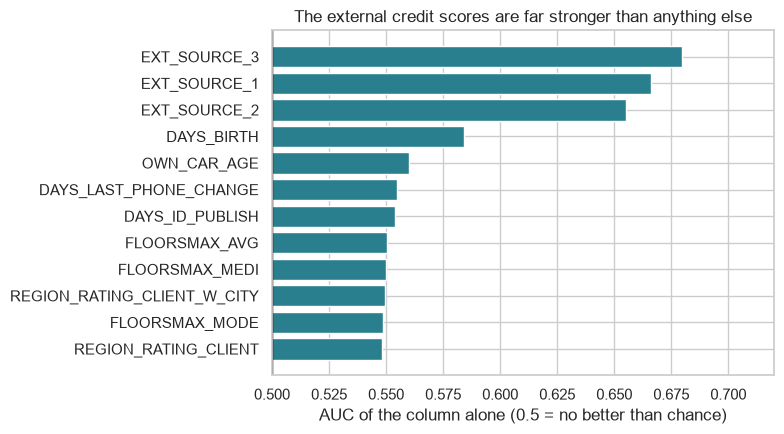

In [4]:
num = dev.select_dtypes("number").drop(columns=["SK_ID_CURR", "TARGET"])
rows = []
for col in num.columns:
    mask = num[col].notna()
    if mask.sum() < 1000 or num.loc[mask, col].nunique() < 2:
        continue
    auc = roc_auc_score(dev.loc[mask, "TARGET"], num.loc[mask, col])
    rows.append((col, max(auc, 1 - auc), mask.mean()))
power = pd.DataFrame(rows, columns=["feature", "auc", "coverage"]).sort_values("auc", ascending=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
top = power.head(12).iloc[::-1]
ax.barh(top["feature"], top["auc"], color="#2a7f8e")
ax.axvline(0.5, color="black", lw=1)
ax.set_xlim(0.5, 0.72)
ax.set_xlabel("AUC of the column alone (0.5 = no better than chance)")
ax.set_title("The external credit scores are far stronger than anything else")
fig.tight_layout()
fig.savefig(FIGS / "single_feature_auc.png", dpi=130)
plt.show()

## How risk changes across the strongest score and age

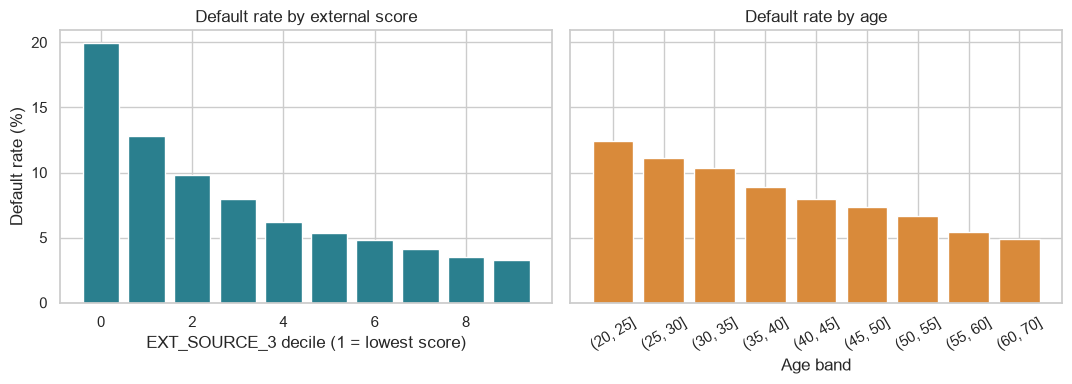

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

d = dev.dropna(subset=["EXT_SOURCE_3"]).copy()
d["bin"] = pd.qcut(d["EXT_SOURCE_3"], 10, duplicates="drop")
rate = d.groupby("bin", observed=True)["TARGET"].mean()
axes[0].bar(range(len(rate)), rate.values * 100, color="#2a7f8e")
axes[0].set_xlabel("EXT_SOURCE_3 decile (1 = lowest score)")
axes[0].set_ylabel("Default rate (%)")
axes[0].set_title("Default rate by external score")

d = dev.assign(age=(-dev["DAYS_BIRTH"] / 365.25))
d["bin"] = pd.cut(d["age"], [20, 25, 30, 35, 40, 45, 50, 55, 60, 70])
rate = d.groupby("bin", observed=True)["TARGET"].mean()
axes[1].bar([str(i) for i in rate.index], rate.values * 100, color="#d98a3a")
axes[1].set_xlabel("Age band")
axes[1].tick_params(axis="x", rotation=30)
axes[1].set_title("Default rate by age")

fig.tight_layout()
fig.savefig(FIGS / "risk_by_score_and_age.png", dpi=130)
plt.show()

**Finding:** risk falls steadily with both, which suits a scorecard. Age and gender both separate risk, so they need care: a real lender may not be allowed to use them. The fairness step compares the model with and without them.

## Groups to watch for fairness

In [6]:
dev.groupby("CODE_GENDER")["TARGET"].agg(applicants="size", default_rate="mean").round(4)

,applicants,default_rate
CODE_GENDER,,
F,161887,0.0700
M,84119,0.1014
XNA,2,0.0000


## Summary

- **Label:** about 8% default, so accuracy is useless (always saying "repays" scores about 92%). Use AUC, KS and calibration.
- **Fix:** `DAYS_EMPLOYED` placeholder, `CODE_GENDER = XNA`, extreme incomes.
- **Missing values:** treat as information, not noise.
- **Strongest signals:** the three `EXT_SOURCE` scores, then age. Their source is not documented, so the project must report results with and without them.
- **Next:** build per-applicant features from the linked tables.